# 04. Neural Network Experiments

## TextCNN for Supervised Topic Classification

This notebook introduces the neural-network component of TopicSense-NLP. It establishes a first deep-learning baseline using a Convolutional Neural Network for text classification (TextCNN).

The experiment uses the 20 Newsgroups benchmark and the existing leakage-aware training and validation split. Its purpose is to determine how a compact neural architecture performs relative to the classical machine-learning baselines established in the preceding notebook.

The implementation is deliberately resource-conscious. It uses trainable word embeddings, a bounded vocabulary, fixed-length sequences and a small convolutional architecture suitable for CPU execution.

The official test partition remains reserved for final evaluation and is not used in this experiment.

## 1. Experimental Scope

The approved experimental register identifies TextCNN as EXP-04 and Bidirectional LSTM as EXP-05.

This notebook implements EXP-04 first. The BiLSTM experiment remains conditional on the feasibility and runtime of the initial neural baseline. Implementing both architectures simultaneously would make it harder to isolate problems and assess resource requirements.

The experiment uses the message-body representation to reduce reliance on newsgroup headers and other message metadata. Unlike the classical feature pipeline, the neural model learns its own word embeddings and does not use a separately fitted TF-IDF or Bag-of-Words representation.

The vocabulary is constructed exclusively from training documents. Validation documents can contain unseen tokens, which are mapped to the unknown-token index.

## 2. Model and Training Design

TextCNN applies several one-dimensional convolution filters to embedded token sequences. Each filter captures local patterns of different lengths. Max pooling reduces each feature map to a fixed-size representation, and a final linear layer produces scores for the topic classes.

The initial configuration uses:

- A maximum vocabulary of 30,000 tokens.
- A minimum token frequency of two.
- A trainable embedding dimension of 64.
- 64 filters for each convolution kernel.
- Kernel sizes of 3, 4 and 5 tokens.
- A dropout rate of 0.5.
- A maximum sequence length of 256 tokens.
- AdamW optimisation and cross-entropy loss.
- Validation macro F1 for checkpoint selection and early stopping.

These are controlled starting settings rather than optimised hyperparameters. The experiment records the configuration and runtime so that any subsequent changes can be evaluated transparently.

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import yaml

from topicsense.training.neural import run_neural_experiments

## 3. Load the Experiment Configuration

The YAML file defines the data locations, text representation, vocabulary limits, model architecture, training settings and output paths.

Keeping these settings outside the notebook makes the experiment reproducible and allows the training script to execute the same configuration independently.

In [4]:
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

CONFIG_PATH = PROJECT_ROOT / "configs" / "neural_networks.yaml"

if not CONFIG_PATH.is_file():
    raise FileNotFoundError(f"Configuration file not found: {CONFIG_PATH}")

with CONFIG_PATH.open("r", encoding="utf-8") as file:
    CONFIG = yaml.safe_load(file)

if not isinstance(CONFIG, dict):
    raise ValueError("The neural-network configuration must be a YAML mapping.")

print(f"Project root: {PROJECT_ROOT}")
print(f"Configuration: {CONFIG_PATH}")

pd.Series(
    {
        "model": "TextCNN",
        "experiment_id": "EXP-04",
        "representation": CONFIG["preprocessing"]["representation"],
        "maximum_vocabulary": CONFIG["vocabulary"]["max_size"],
        "embedding_dimension": CONFIG["model"]["embedding_dim"],
        "convolution_kernels": CONFIG["model"]["kernel_sizes"],
        "maximum_sequence_length": CONFIG["training"]["max_sequence_length"],
        "batch_size": CONFIG["training"]["batch_size"],
        "configured_epochs": CONFIG["training"]["epochs"],
        "random_seed": CONFIG["project"]["random_seed"],
    },
    name="Configured value",
)

Project root: /home/nkululekocyrilcele/projects/topicsense-nlp
Configuration: /home/nkululekocyrilcele/projects/topicsense-nlp/configs/neural_networks.yaml


model                           TextCNN
experiment_id                    EXP-04
representation             message_body
maximum_vocabulary                30000
embedding_dimension                  64
convolution_kernels           [3, 4, 5]
maximum_sequence_length             256
batch_size                           64
configured_epochs                     5
random_seed                          42
Name: Configured value, dtype: object

## 4. Verify the Development Split

The experiment uses the existing official-training split manifest. Its training and validation identifiers were generated during preprocessing, with duplicate-connected documents kept within the same partition.

The following checks confirm that the two identifier sets are non-empty, disjoint and drawn from the expected manifest. The training implementation independently validates these conditions and filters the raw dataset to official training records only.

No official test records are supplied to the vocabulary builder, optimiser, checkpoint-selection procedure or validation evaluator.

In [5]:
SPLIT_PATH = PROJECT_ROOT / CONFIG["data"]["split_manifest_path"]

with SPLIT_PATH.open("r", encoding="utf-8") as file:
    SPLIT_MANIFEST = json.load(file)

TRAINING_IDS = set(SPLIT_MANIFEST["training_record_ids"])
VALIDATION_IDS = set(SPLIT_MANIFEST["validation_record_ids"])

assert TRAINING_IDS
assert VALIDATION_IDS
assert TRAINING_IDS.isdisjoint(VALIDATION_IDS)

split_summary = pd.Series(
    {
        "Training documents": len(TRAINING_IDS),
        "Validation documents": len(VALIDATION_IDS),
        "Training-validation overlap": len(TRAINING_IDS & VALIDATION_IDS),
        "Split method": SPLIT_MANIFEST.get("method", "Not recorded"),
        "Random seed": SPLIT_MANIFEST.get("random_seed", "Not recorded"),
    },
    name="Value",
)

display(split_summary.to_frame())

,Value
Training documents,9051
Validation documents,2263
Training-validation overlap,0
Split method,StratifiedGroupKFold over duplicate-connected ...
Random seed,42


## 5. Train and Validate TextCNN

The training function below executes the configured experiment.

At the end of each epoch, the model is evaluated on the validation partition. The checkpoint with the highest validation macro F1 is retained. Training stops when the configured number of consecutive epochs passes without an improvement.

The final metrics are calculated using that selected checkpoint. The official test partition remains excluded.

Training can take considerably longer than the classical baselines on CPU. The recorded duration should therefore be interpreted in the context of the available hardware.

In [6]:
EXPERIMENT_RESULTS = run_neural_experiments(
    CONFIG,
    project_root=PROJECT_ROOT,
)

assert len(EXPERIMENT_RESULTS["runs"]) == 1

TEXTCNN_RUN = EXPERIMENT_RESULTS["runs"][0]

print("TextCNN training and validation completed.")
print(f"Run ID: {TEXTCNN_RUN['run_id']}")
print(f"Best epoch: {TEXTCNN_RUN['best_epoch']}")
print(f"Metrics: {EXPERIMENT_RESULTS['metrics_csv']}")
print(f"Detailed results: {EXPERIMENT_RESULTS['results_json']}")

Epoch 1/5 | loss=3.1972 | validation_macro_f1=0.1271
Epoch 2/5 | loss=2.9182 | validation_macro_f1=0.2199
Epoch 3/5 | loss=2.6955 | validation_macro_f1=0.3886
Epoch 4/5 | loss=2.4337 | validation_macro_f1=0.4880
Epoch 5/5 | loss=2.1994 | validation_macro_f1=0.5078
TextCNN training and validation completed.
Run ID: textcnn__message_body
Best epoch: 5
Metrics: /home/nkululekocyrilcele/projects/topicsense-nlp/results/metrics/neural_networks.csv
Detailed results: /home/nkululekocyrilcele/projects/topicsense-nlp/results/logs/neural_networks.json


## 6. Aggregate Validation Performance

The aggregate metrics provide the first quantitative view of the TextCNN baseline.

Macro F1 is the primary selection metric because it gives each topic category equal weight. Accuracy and weighted F1 provide complementary views of overall classification performance.

These values describe the validation partition only. They are not final test-set results.

In [7]:
SUMMARY = pd.DataFrame(EXPERIMENT_RESULTS["summary"])

display(
    SUMMARY[
        [
            "model",
            "training_documents",
            "validation_documents",
            "vocabulary_size",
            "best_epoch",
            "accuracy",
            "macro_precision",
            "macro_recall",
            "macro_f1",
            "weighted_f1",
        ]
    ].round(4)
)

,model,training_documents,validation_documents,vocabulary_size,best_epoch,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1
0,TextCNN,9051,2263,30000,5,0.5166,0.634,0.5091,0.5078,0.5106


## 7. Training History

The training history records the average training loss and validation performance at each completed epoch.

Training loss describes the model's fit to the training data. Validation macro F1 indicates how well the model performs on documents that were not used to update its parameters.

The two measures should be considered together. A decreasing training loss does not necessarily imply improving validation performance. The selected checkpoint is determined by validation macro F1 rather than by the final training loss.

In [8]:
HISTORY = pd.DataFrame(TEXTCNN_RUN["history"])

display(HISTORY.round(4))

,epoch,training_loss,validation_accuracy,validation_macro_f1
0,1,3.1972,0.1737,0.1271
1,2,2.9182,0.2740,0.2199
2,3,2.6955,0.4224,0.3886
3,4,2.4337,0.4901,0.4880
4,5,2.1994,0.5166,0.5078


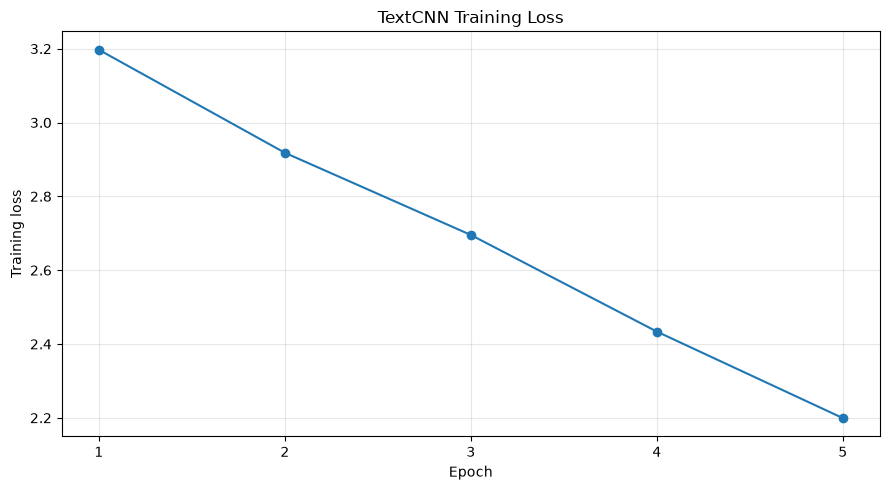

In [9]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    HISTORY["epoch"],
    HISTORY["training_loss"],
    marker="o",
)

ax.set(
    title="TextCNN Training Loss",
    xlabel="Epoch",
    ylabel="Training loss",
)

ax.set_xticks(HISTORY["epoch"])
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

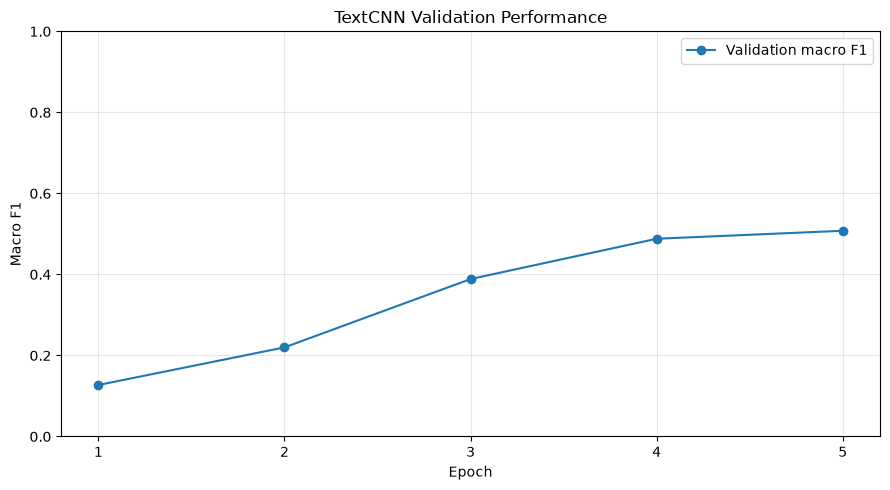

In [10]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    HISTORY["epoch"],
    HISTORY["validation_macro_f1"],
    marker="o",
    label="Validation macro F1",
)

ax.set(
    title="TextCNN Validation Performance",
    xlabel="Epoch",
    ylabel="Macro F1",
)

ax.set_xticks(HISTORY["epoch"])
ax.set_ylim(0, 1)
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

## 8. Per-Class Validation Performance

Aggregate metrics can conceal differences between individual categories. The per-class report makes it possible to identify categories where the model performs relatively well and those where precision, recall or F1 remains weaker.

Support indicates the number of validation documents belonging to each actual category. Differences in support should be considered when interpreting the class-level results.

In [11]:
PER_CLASS = pd.DataFrame(TEXTCNN_RUN["metrics"]["per_class"]).T

PER_CLASS.index.name = "class_label"

display(
    PER_CLASS[["precision", "recall", "f1_score", "support"]]
    .sort_values("f1_score", ascending=True)
    .round(4)
)

,precision,recall,f1_score,support
class_label,,,,
comp.sys.mac.hardware,0.6000,0.0261,0.0500,115.0
sci.electronics,0.3488,0.2521,0.2927,119.0
talk.religion.misc,0.7500,0.1974,0.3125,76.0
comp.sys.ibm.pc.hardware,0.3029,0.5339,0.3865,118.0
comp.graphics,0.4660,0.4138,0.4384,116.0
sci.crypt,0.2955,0.8739,0.4416,119.0
rec.sport.baseball,0.6984,0.3697,0.4835,119.0
talk.politics.misc,1.0000,0.3226,0.4878,93.0
sci.med,0.7719,0.3697,0.5000,119.0


## 9. Confusion Matrix

The confusion matrix shows how actual validation categories are distributed across the model's predicted categories.

Rows represent actual classes and columns represent predicted classes. Values along the diagonal correspond to correct predictions, while off-diagonal values represent classification errors.

The matrix provides a class-level view of the errors made by TextCNN. Individual misclassified documents can be investigated in the dedicated error-analysis stage.

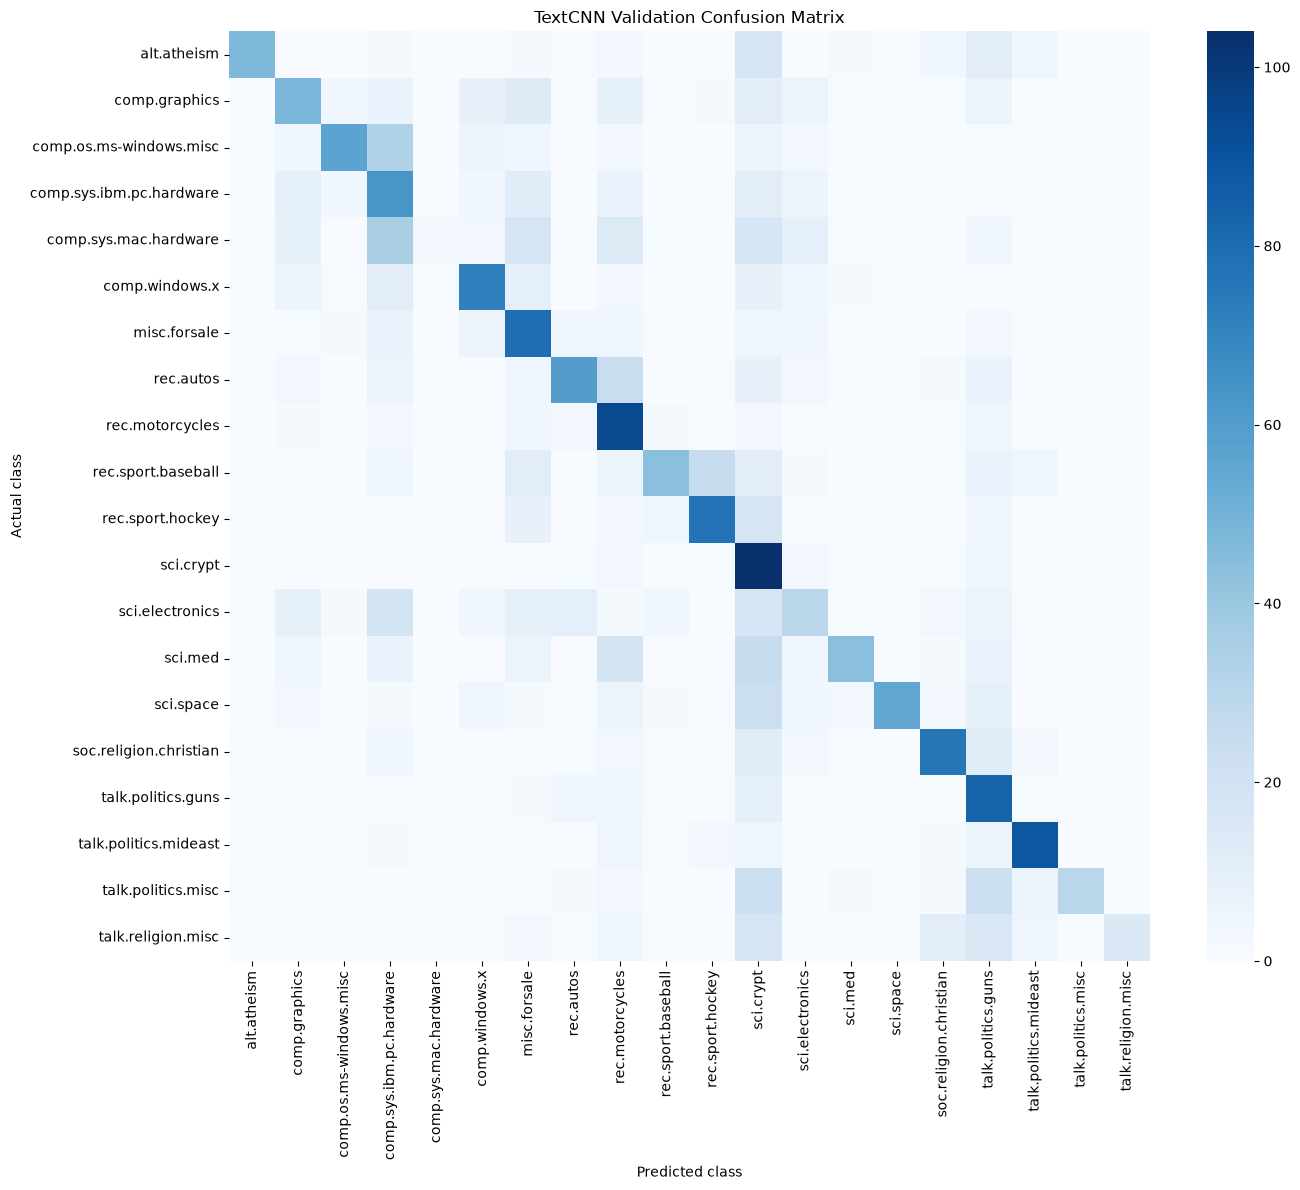

In [12]:
CLASS_LABELS = TEXTCNN_RUN["metrics"]["class_labels"]
CONFUSION_MATRIX = pd.DataFrame(
    TEXTCNN_RUN["metrics"]["confusion_matrix"],
    index=CLASS_LABELS,
    columns=CLASS_LABELS,
)

fig, ax = plt.subplots(figsize=(14, 12))

sns.heatmap(
    CONFUSION_MATRIX,
    cmap="Blues",
    ax=ax,
    xticklabels=True,
    yticklabels=True,
)

ax.set(
    title="TextCNN Validation Confusion Matrix",
    xlabel="Predicted class",
    ylabel="Actual class",
)

plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## 10. Computational Performance

Neural-network performance must be considered alongside its computational cost.

The measurements below include total fitting time, validation prediction time, average prediction latency, throughput and the serialised model artifact size.

The prediction measurements were collected on the validation partition using the configured batch size. They should not be treated as production-serving benchmarks.

The artifact size is measured from the serialised model checkpoint payload. It includes the learned model parameters and the vocabulary and metadata required to interpret the checkpoint.

In [13]:
efficiency_summary = pd.Series(
    {
        "Training duration (seconds)": TEXTCNN_RUN["fit_seconds"],
        "Validation prediction duration (seconds)": (TEXTCNN_RUN["prediction_seconds"]),
        "Average latency (milliseconds/document)": (
            TEXTCNN_RUN["latency_ms_per_document"]
        ),
        "Throughput (documents/second)": (
            TEXTCNN_RUN["throughput_documents_per_second"]
        ),
        "Model artifact size (bytes)": TEXTCNN_RUN["artifact_size_bytes"],
        "Best epoch": TEXTCNN_RUN["best_epoch"],
        "Vocabulary size": TEXTCNN_RUN["vocabulary_size"],
    },
    name="Measured value",
)

display(efficiency_summary.to_frame().round(4))

,Measured value
Training duration (seconds),9.339180e+01
Validation prediction duration (seconds),1.531000e+00
Average latency (milliseconds/document),6.765000e-01
Throughput (documents/second),1.478121e+03
Model artifact size (bytes),8.472683e+06
Best epoch,5.000000e+00
Vocabulary size,3.000000e+04


## 11. Output and Reproducibility Checks

The experiment produces a metrics CSV and a detailed JSON record. The detailed record includes the selected model's validation metrics, training history, configuration and computational measurements.

The checks below verify that the expected outputs exist and that the run metadata correctly identifies the experiment as a validation-only evaluation.

Model checkpoints are not persisted by default. This avoids creating unnecessary large artifacts during the initial feasibility experiment. Checkpoint persistence can be enabled through the YAML configuration when a trained model needs to be retained.

In [14]:
METRICS_PATH = PROJECT_ROOT / EXPERIMENT_RESULTS["metrics_csv"]
RESULTS_PATH = PROJECT_ROOT / EXPERIMENT_RESULTS["results_json"]

with RESULTS_PATH.open("r", encoding="utf-8") as file:
    SAVED_RESULTS = json.load(file)

assert METRICS_PATH.is_file()
assert RESULTS_PATH.is_file()
assert SAVED_RESULTS["test_data_used"] is False
assert SAVED_RESULTS["runs"][0]["experiment_id"] == "EXP-04"

print("Output validation passed.")
print(f"Metrics CSV: {METRICS_PATH}")
print(f"Detailed results: {RESULTS_PATH}")
print(f"Test data used: {SAVED_RESULTS['test_data_used']}")

Output validation passed.
Metrics CSV: /home/nkululekocyrilcele/projects/topicsense-nlp/results/metrics/neural_networks.csv
Detailed results: /home/nkululekocyrilcele/projects/topicsense-nlp/results/logs/neural_networks.json
Test data used: False


## 12. Experimental Interpretation and Limitations

The TextCNN results establish an initial neural-network reference point for the 20 Newsgroups classification task. Their interpretation should consider the validation metrics, class-level performance, training history and computational measurements together.

The experiment uses a relatively small randomly initialised embedding layer and a limited number of training epochs. It is therefore a controlled baseline, not an extensively tuned neural architecture.

The following limitations should be kept in view:

- The vocabulary is learned only from the training partition.
- Documents are truncated or padded to a fixed sequence length.
- The model uses the message-body representation rather than the full message.
- Embeddings are learned from the available training data.
- Hyperparameters have not yet been optimised.
- Validation results do not establish final test performance.
- Runtime measurements are specific to the recorded CPU environment.

The results will be compared with the classical baselines in the later model-comparison stage. No conclusion about the superiority of neural networks should be drawn from this experiment alone.

A Bidirectional LSTM may be investigated as EXP-05 if the TextCNN results and measured resource requirements justify continuing with a second neural architecture.